# Completion delle feature del dataset Breast Cancer: media, regressione lineare, Ridge, PCA e SVD

**Obiettivo.** Partiamo da una matrice di 569 osservazioni e 30 feature numeriche, con valori portati nell'intervallo $[0,1]$. Nascondiamo alcune celle e confrontiamo **nove metodi**:

1. media della colonna calcolata sul training;
2. regressione lineare addestrata sul training completo;
3. regressione lineare addestrata sul training mascherato;
4. Ridge regression addestrata sul training completo;
5. Ridge regression addestrata sul training mascherato;
6. PCA iterativa, che alterna proiezione e ripristino delle celle osservate;
7. SVD esplicita del training, seguita dalla stima dei coefficienti di ciascuna riga sulle sole celle osservate;
8. PCA iterativa con rango fisso $r=6$;
9. SVD esplicita con rango fisso $r=6$.

Ogni riga rappresenta un'osservazione del dataset Breast Cancer Wisconsin Diagnostic; ogni colonna è una feature. La completion sfrutta le relazioni statistiche tra colonne per stimare valori non osservati. Il confronto usa solo le celle nascoste nelle maschere di validation e test.


**Copia matriciale:** regressioni multi-output secondo §3.2.1 di CompletionAgent_1.0; 27 predittori comuni, tre output, training mascherato complete-case.


## 1. Notazione e criteri di valutazione

Indichiamo con $X$ la matrice normalizzata. La maschera $M$ ha la stessa forma di $X$: $M_{ij}=1$ significa che il valore della riga $i$ e della feature $j$ è osservato; $M_{ij}=0$ significa che è nascosto. L'insieme $\Omega=\{(i,j):M_{ij}=0\}$ contiene le celle su cui calcoliamo gli errori. La matrice $\widehat X$ contiene le stime.

**Errore quadratico medio con radice (RMSE):**

$$
\mathrm{RMSE}=\sqrt{\frac{1}{|\Omega|}\sum_{(i,j)\in\Omega}(X_{ij}-\widehat X_{ij})^2}
$$

**Errore assoluto medio (MAE):**

$$
\mathrm{MAE}=\frac{1}{|\Omega|}\sum_{(i,j)\in\Omega}|X_{ij}-\widehat X_{ij}|
$$

Valori più bassi sono migliori. La tabella finale riporta anche $R^2$, calcolato trattando tutte le celle nascoste di uno split come un unico insieme di valori. Prima delle metriche, le stime vengono limitate a $[0,1]$.

PCA e SVD trovano direzioni dello stesso sottospazio quando sono applicate alla medesima matrice centrata. Qui diventano **due metodi di completion distinti**: la PCA aggiorna iterativamente i valori mancanti, mentre la SVD adatta direttamente i coefficienti di ogni riga alle coordinate osservate. Entrambi scelgono il proprio rango sull'RMSE della validation.


In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler

SEED = 42
rng = np.random.default_rng(SEED)
hidden_fraction = 0.30
selected_features = [0, 6, 20]  # mean radius, mean concavity, worst radius

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_context("notebook")
np.set_printoptions(precision=4, suppress=True)
print(f"Quota nascosta nelle feature selezionate = {hidden_fraction:.0%}")


Quota nascosta nelle feature selezionate = 30%


## 2. Dataset, split e normalizzazione

Carichiamo le 569 osservazioni e le 30 feature numeriche del dataset Breast Cancer Wisconsin Diagnostic. Il codice permuta le righe, crea gli insiemi disgiunti di training, validation e test, poi addestra `MinMaxScaler` **solo sul training**.

Per ogni feature, la trasformazione `MinMaxScaler` porta minimo e massimo del training a 0 e 1. Validation e Test usano gli stessi parametri imparati per `MinMaxScaler`; eventuali valori fuori dall'intervallo visto nel training sono limitati a $[0,1]$. La matrice completa trasformata serve alle statistiche descrittive, non all'addestramento dei modelli.


In [35]:
dataset = load_breast_cancer()
X_raw = dataset.data.astype(float)
feature_names = [name.replace(" ", "_") for name in dataset.feature_names]
n, d = X_raw.shape

# Split disgiunto prima del preprocessing
indices = rng.permutation(n)
n_train, n_val = int(.75*n), int(.15*n)
idx_train = indices[:n_train]
idx_val = indices[n_train:n_train+n_val]
idx_test = indices[n_train+n_val:]
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_raw[idx_train])
X_val = np.clip(scaler.transform(X_raw[idx_val]), 0, 1)
X_test = np.clip(scaler.transform(X_raw[idx_test]), 0, 1)
X = np.clip(scaler.transform(X_raw), 0, 1)  # descrizione, non usata per fit
X_df = pd.DataFrame(X, columns=feature_names)
print("Dataset: Breast Cancer Wisconsin Diagnostic")
print("Shape:", X.shape, "| train/val/test:", X_train.shape, X_val.shape, X_test.shape)
display(X_df.head())


Dataset: Breast Cancer Wisconsin Diagnostic
Shape: (569, 30) | train/val/test: (426, 30) (85, 30) (58, 30)


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,...,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension
0,0.538627,0.022658,0.552093,0.363733,0.698712,0.884255,0.703799,0.768949,0.686364,0.603178,...,0.620776,0.141525,0.668310,0.450698,0.601136,0.619292,0.568610,0.912027,0.598462,0.418864
1,0.664856,0.272574,0.622668,0.501591,0.277910,0.202931,0.203799,0.366806,0.379798,0.136229,...,0.606901,0.303571,0.539818,0.435214,0.347553,0.154563,0.192971,0.639175,0.233590,0.222878
2,0.621801,0.390260,0.602404,0.449417,0.588699,0.481200,0.462946,0.668583,0.509596,0.206568,...,0.556386,0.360075,0.508442,0.374508,0.483590,0.385375,0.359744,0.835052,0.403706,0.213433
3,0.217183,0.360839,0.236112,0.102906,1.000000,0.905828,0.566135,0.549922,0.776263,1.000000,...,0.248310,0.385928,0.241347,0.094008,0.915472,0.814012,0.548642,0.884880,1.000000,0.773711
4,0.651157,0.156578,0.638041,0.489290,0.472434,0.388398,0.464353,0.545217,0.378283,0.181992,...,0.519744,0.123934,0.506948,0.341575,0.437364,0.172415,0.319489,0.558419,0.157500,0.142595


## 3. PCA esplorativa e statistiche descrittive

La PCA è calcolata sulle 30 feature normalizzate del **training completo**, prima di applicare le maschere. La varianza cumulativa dopo $r$ componenti è la somma delle quote di varianza spiegata dalle prime $r$ componenti. Il codice mostra la tabella, il grafico e il primo rango che raggiunge il 90%; 

Notiamo che *almeno* 6 componenti principali sono necessarie per rappresentare il 90% della variaza. Questo valore descrive la compressione del training e non determina il rango della completion: quello viene scelto più avanti sull'errore delle celle nascoste nella validation. Le statistiche per colonna e la matrice di correlazione descrivono la matrice normalizzata prima della mascheratura.


,componente,varianza_spiegata,varianza_cumulativa
0,1,0.5252,0.5252
1,2,0.1772,0.7024
2,3,0.0659,0.7683
3,4,0.0627,0.8309
4,5,0.0464,0.8774
5,6,0.0329,0.9103
6,7,0.0151,0.9254
7,8,0.0125,0.9379
8,9,0.0111,0.9489
9,10,0.0099,0.9588


Prime 6 componenti per raggiungere il 90% della varianza


,media,deviazione standard,min,max
mean_radius,0.3496,0.1722,0.0,1.0
mean_texture,0.3240,0.1455,0.0,1.0
mean_perimeter,0.3366,0.1697,0.0,1.0
mean_area,0.2169,0.1493,0.0,1.0
mean_smoothness,0.4229,0.1732,0.0,1.0
mean_compactness,0.2907,0.1800,0.0,1.0
mean_concavity,0.2083,0.1870,0.0,1.0
mean_concave_points,0.2556,0.2025,0.0,1.0
mean_symmetry,0.3796,0.1385,0.0,1.0
mean_fractal_dimension,0.2661,0.1496,0.0,1.0


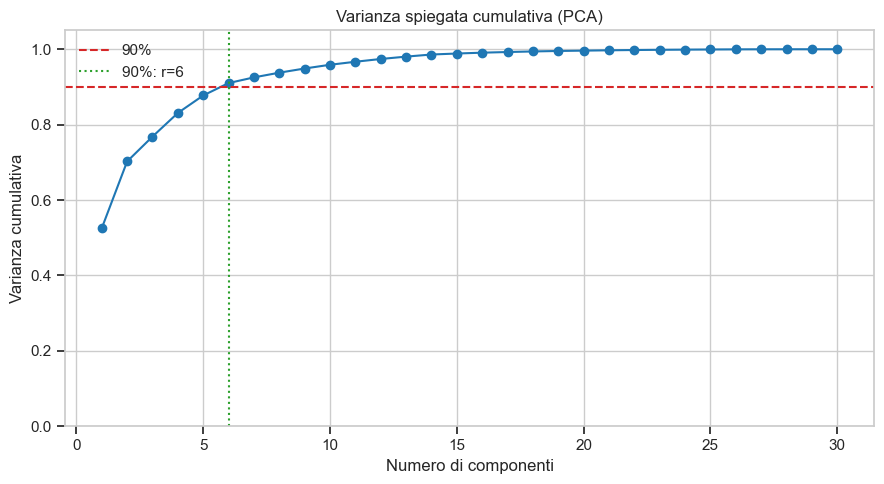

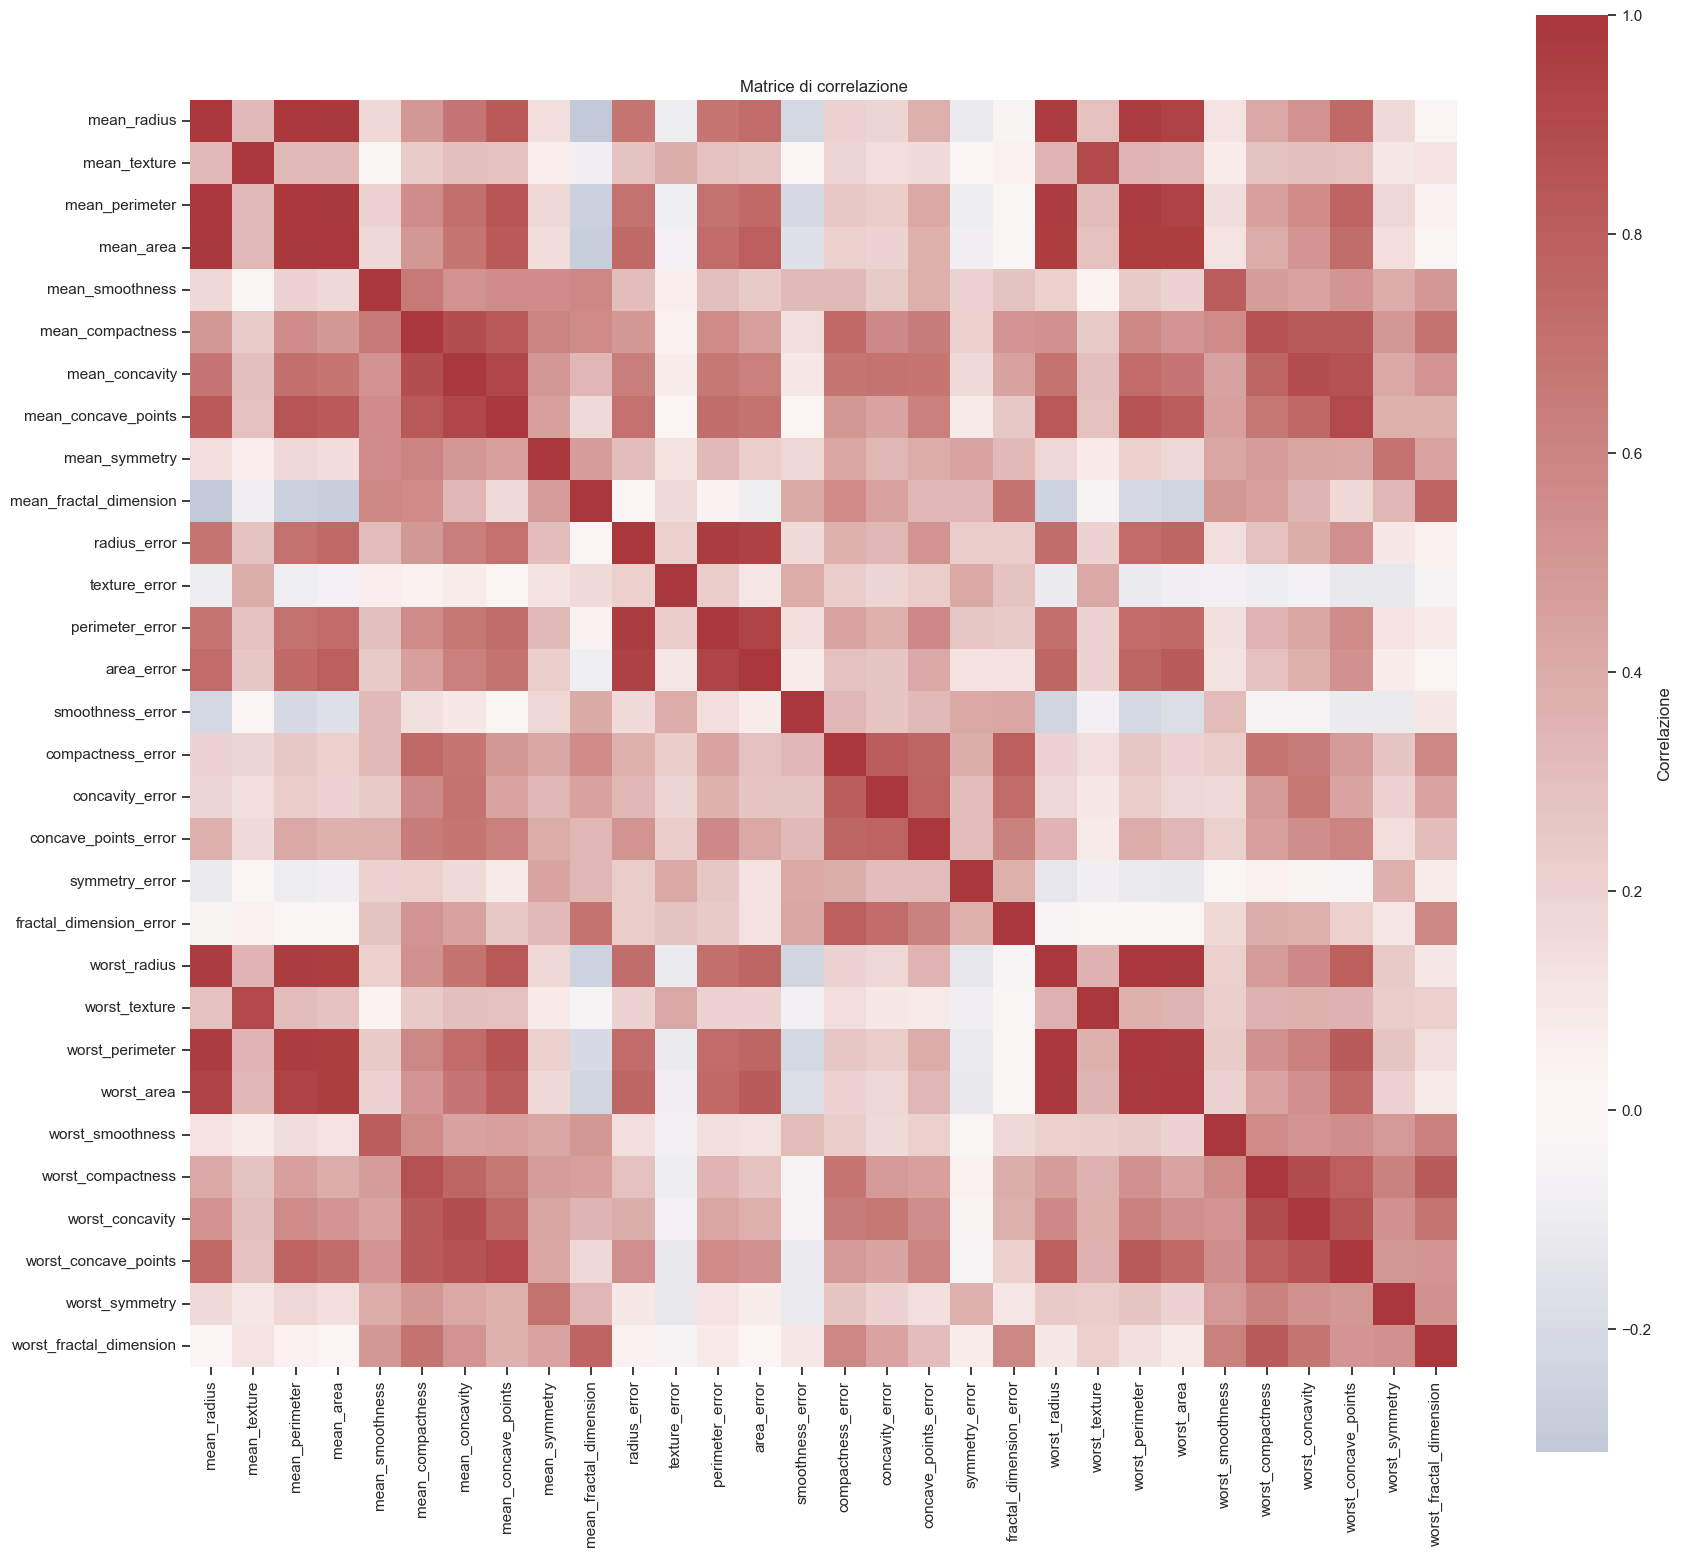

In [36]:
pca_full = PCA().fit(X_train)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)
variance_table = pd.DataFrame({
    "componente": np.arange(1, d + 1),
    "varianza_spiegata": explained,
    "varianza_cumulativa": cumulative,
})
display(variance_table.round(4))
rank_90 = int(np.searchsorted(cumulative, .90) + 1)
print(f"Prime {rank_90} componenti per raggiungere il 90% della varianza")

summary = X_df.agg(["mean", "std", "min", "max"]).T
display(summary.round(4).rename(columns={"mean": "media", "std": "deviazione standard"}))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(1, d+1), cumulative, "o-", color="tab:blue")
ax.axhline(.90, color="tab:red", ls="--", label="90%")
ax.axvline(rank_90, color="tab:green", ls=":", label=f"90%: r={rank_90}")
ax.set(xlabel="Numero di componenti", ylabel="Varianza cumulativa", ylim=(0, 1.05))
ax.set_title("Varianza spiegata cumulativa (PCA)")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(18, 16))
sns.heatmap(
    X_df.corr(),
    annot=False,
    cmap="vlag",
    center=0,
    square=True,
    cbar_kws={"label": "Correlazione"},
    ax=ax,
)
ax.set_title("Matrice di correlazione")
plt.tight_layout()
plt.show()


## 4. Maschere di osservazione

La funzione `make_mask` può nascondere soltanto le feature indicate in `selected_features`: `mean_radius`, `mean_concavity` e `worst_radius` nel confronto principale. Per ogni riga e per ciascuna di queste tre colonne, estrae separatamente un valore casuale e nasconde la cella con probabilità 30%. Quindi una riga può avere zero, una o più feature target nascoste; il 30% è una probabilità per colonna, non una quota esatta di tutte le 30 colonne. Sul totale della matrice ci si aspetta circa il 3% di celle nascoste.

Il codice crea maschere riproducibili per training, validation e test usando seed distinti. Le 27 feature non selezionate restano sempre osservate. La maschera del training è usata in alcuni modelli specifici, così da analizzare come influisce la mancanza di completezza dei dati nella fase di allenamento.


In [37]:
# Split già creato prima del preprocessing, per evitare leakage.
print("Dimensioni:", X_train.shape, X_val.shape, X_test.shape)

def make_mask(n_rows, d, selected, hidden_fraction, seed=0):
    'M=1 osservato, M=0 nascosto; maschera solo feature selezionate.'
    if not 0 <= hidden_fraction <= 1:
        raise ValueError("hidden_fraction deve appartenere a [0, 1]")
    M = np.ones((n_rows, d), dtype=bool)
    local_rng = np.random.default_rng(seed)
    for j in selected:
        hidden = local_rng.random(n_rows) < hidden_fraction
        M[hidden, j] = False
    return M

M_train = make_mask(len(X_train), d, selected_features, hidden_fraction, seed=100)
M_val = make_mask(len(X_val), d, selected_features, hidden_fraction, seed=101)
M_test = make_mask(len(X_test), d, selected_features, hidden_fraction, seed=202)
hidden_val = ~M_val
hidden_test = ~M_test
print("Entry nascoste training:", (~M_train).sum(), f"({(~M_train).mean():.1%})")
print("Entry nascoste validation:", hidden_val.sum(), f"({hidden_val.mean():.1%})")
print("Entry nascoste test:", hidden_test.sum(), f"({hidden_test.mean():.1%})")
print("Feature candidati:", [feature_names[j] for j in selected_features])


Dimensioni: (426, 30) (85, 30) (58, 30)
Entry nascoste training: 353 (2.8%)
Entry nascoste validation: 74 (2.9%)
Entry nascoste test: 50 (2.9%)
Feature candidati: ['mean_radius', 'mean_concavity', 'worst_radius']


In [38]:
def masked_view(X_true, M):
    'Restituisce una copia con NaN nelle entry non osservate.'
    X_obs = X_true.copy()
    X_obs[~M] = np.nan
    return X_obs

def observed_with_mean(X_true, M, means):
    'Input disponibile al modello: osservato reale, nascosto inizializzato alla media.'
    X_obs = X_true.copy()
    X_obs[~M] = np.broadcast_to(means, X_true.shape)[~M]
    return X_obs

def evaluate(X_true, X_hat, M, method, split):
    hidden = ~M
    y_true, y_hat = X_true[hidden], np.clip(X_hat[hidden], 0, 1)
    return {
        "split": split,
        "metodo": method,
        "RMSE": np.sqrt(mean_squared_error(y_true, y_hat)),
        "MAE": mean_absolute_error(y_true, y_hat),
        "R2": r2_score(y_true, y_hat),
        "entry valutate": int(hidden.sum()),
    }

display(pd.DataFrame({
    "validation": M_val[:, selected_features].mean(axis=0),
    "test": M_test[:, selected_features].mean(axis=0),
}, index=[feature_names[j] for j in selected_features]).rename(columns={"validation": "frazione osservata validation", "test": "frazione osservata test"}))


,frazione osservata validation,frazione osservata test
mean_radius,0.752941,0.672414
mean_concavity,0.694118,0.706897
worst_radius,0.682353,0.758621


## 5. Baseline: media della feature

Per ogni colonna calcoliamo la media sul training completo. Una cella nascosta della colonna $j$ riceve quella media:

$$
\widehat X_{ij}=\overline X_{\mathrm{train},j}\qquad\text{se }M_{ij}=0
$$

Le celle osservate restano uguali all'input. Questa baseline non usa le relazioni tra feature e fornisce un riferimento per giudicare gli altri metodi. La stessa media inizializza anche le celle mancanti nell'input della regressione standard e della PCA iterativa.


In [39]:
column_means = X_train.mean(axis=0)

def mean_completion(X_true, M, means):
    X_hat = X_true.copy()
    X_hat[~M] = np.broadcast_to(means, X_true.shape)[~M]
    return np.clip(X_hat, 0, 1)

X_val_input = observed_with_mean(X_val, M_val, column_means)
X_test_input = observed_with_mean(X_test, M_test, column_means)

# Completed
X_val_mean = mean_completion(X_val_input, M_val, column_means)
X_test_mean = mean_completion(X_test_input, M_test, column_means)


## 6. Completion matriciale multi-output

Le 27 feature esterne al gruppo target sono gli input comuni; i tre target formano $Y\in\mathbb{R}^{n\times3}$. Non si usano altri target come predittori, neppure quando osservati.

Dopo standardizzazione sul solo training, aggiungiamo l'intercetta alla matrice di progetto: $\widetilde X\in\mathbb{R}^{n\times28}$. Stimiamo
$$W=\arg\min_B\|Y-\widetilde X B\|_F^2,\qquad \widehat Y=\widetilde XW,$$
con $W\in\mathbb{R}^{28\times3}$ e `np.linalg.lstsq`. Ogni colonna di W corrisponde a un output. La completion scrive le previsioni soltanto nelle celle nascoste, conservando esattamente quelle osservate. Il clipping delle previsioni a [0,1] è un postprocessing successivo alla mappa affine.

I target mancanti possono restare NaN: non entrano nel prodotto matriciale. Gli input riempiti con medie sono mantenuti per gli altri metodi del confronto, ma la regressione ne legge soltanto le 27 coordinate osservate.


In [40]:
def fit_matrix_completion(X_train, target_features, estimator_factory, rows=None):
    """Cap. 3.2.1: un'unica matrice W per tutti gli output."""
    targets = np.asarray(target_features, dtype=int)
    predictors = np.setdiff1d(np.arange(X_train.shape[1]), targets)
    if rows is None:
        rows = np.ones(len(X_train), dtype=bool)
    if not rows.any():
        raise ValueError("Nessuna riga con tutti i target osservati")
    scaler_inputs = StandardScaler().fit(X_train[rows][:, predictors])
    Z = scaler_inputs.transform(X_train[rows][:, predictors])
    design = np.column_stack([np.ones(len(Z)), Z])
    Y = X_train[rows][:, targets]
    estimator = estimator_factory()
    if isinstance(estimator, Ridge):
        # Ridge matriciale: intercetta non penalizzata.
        penalty = np.eye(design.shape[1])
        penalty[0, 0] = 0.0
        W = np.linalg.solve(design.T @ design + estimator.alpha * penalty,
                            design.T @ Y)
    else:
        # Minimi quadrati multi-output, senza invertire la matrice di Gram.
        W = np.linalg.lstsq(design, Y, rcond=None)[0]
    model = dict(W=W, targets=targets, scaler=scaler_inputs,
                 n_training_rows=int(rows.sum()))
    return model, predictors


def fit_regression_completion(X_train, target_features, estimator_factory):
    return fit_matrix_completion(X_train, target_features, estimator_factory)


def fit_masked_regression_completion(X_train, M_train, target_features, estimator_factory):
    # Complete-case: stessa matrice X e stesse righe per tutti gli output Y.
    rows = M_train[:, target_features].all(axis=1)
    predictors = np.setdiff1d(np.arange(X_train.shape[1]), target_features)
    if not M_train[:, predictors].all():
        raise ValueError("I 27 predittori devono essere osservati")
    model, predictors = fit_matrix_completion(
        X_train, target_features, estimator_factory, rows=rows)
    counts = M_train.sum(axis=0)
    means = np.divide(np.where(M_train, X_train, 0).sum(axis=0), counts,
                      out=np.zeros(X_train.shape[1]), where=counts > 0)
    # Le medie servono agli altri metodi; la regressione non le legge.
    return model, predictors, means


def regression_completion(X_input, M, models, predictors):
    """Predice insieme i tre target e scrive soltanto nelle celle nascoste."""
    if not M[:, predictors].all():
        raise ValueError("Predittori mancanti: questa mappa richiede le 27 feature osservate")
    Z = models['scaler'].transform(X_input[:, predictors])
    design = np.column_stack([np.ones(len(Z)), Z])
    Y_hat = design @ models['W']
    X_hat = X_input.copy()
    for k, target in enumerate(models['targets']):
        missing = ~M[:, target]
        X_hat[missing, target] = np.clip(Y_hat[missing, k], 0, 1)
    return X_hat

linear_models, linear_predictors = fit_regression_completion(
    X_train, selected_features, LinearRegression
)
masked_linear_models, masked_linear_predictors, masked_train_means = (
    fit_masked_regression_completion(
        X_train, M_train, selected_features, LinearRegression
    )
)

X_val_masked_input = observed_with_mean(X_val, M_val, masked_train_means)
X_test_masked_input = observed_with_mean(X_test, M_test, masked_train_means)
X_val_linear = regression_completion(
    X_val_input, M_val, linear_models, linear_predictors
)
X_test_linear = regression_completion(
    X_test_input, M_test, linear_models, linear_predictors
)
X_val_linear_masked = regression_completion(
    X_val_masked_input, M_val, masked_linear_models, masked_linear_predictors
)
X_test_linear_masked = regression_completion(
    X_test_masked_input, M_test, masked_linear_models, masked_linear_predictors
)

print("Forma W (intercetta + 27 predittori, 3 output):", linear_models['W'].shape)
print("Righe training completo / complete-case:",
      linear_models['n_training_rows'], masked_linear_models['n_training_rows'])
# Le celle target possono restare NaN: le predizioni non dipendono dal loro riempimento.
nan_input = masked_view(X_test, M_test)
nan_completion = regression_completion(nan_input, M_test, linear_models, linear_predictors)
np.testing.assert_allclose(nan_completion, X_test_linear)
np.testing.assert_array_equal(nan_completion[M_test], X_test[M_test])
# OLS matriciale equivale a tre fit scalari con stessi predittori e righe.
Z_check = linear_models['scaler'].transform(X_train[:, linear_predictors])
D_check = np.column_stack([np.ones(len(Z_check)), Z_check])
for k, target in enumerate(selected_features):
    scalar_w = np.linalg.lstsq(D_check, X_train[:, target], rcond=None)[0]
    np.testing.assert_allclose(D_check @ scalar_w,
                               D_check @ linear_models['W'][:, k], atol=1e-10)


Forma W (intercetta + 27 predittori, 3 output): (28, 3)
Righe training completo / complete-case: 426 166


### Variante con training mascherato: righe complete sui tre target

Si selezionano le righe nelle quali tutti e tre i target sono osservati. La stessa matrice dei 27 predittori e le stesse righe sono quindi usate per tutte le colonne di Y, senza imputare le risposte. Questa scelta riduce i dati disponibili rispetto ai fit separati per target dell'originale. Non è una regressione con perdita su singole risposte osservate: è OLS multi-output su righe complete.


## 7. Ridge matriciale multi-output

Si usano gli stessi 27 predittori e tre output della OLS. Si risolve il problema con penalizzazione L2 dei coefficienti e intercetta non penalizzata. La variante mascherata usa le stesse righe complete definite sopra. Alpha resta 1.0 per il confronto con l'originale.


In [41]:
ridge_alpha = 1.0

def ridge_estimator():
    return Ridge(alpha=ridge_alpha)

ridge_models, ridge_predictors = fit_regression_completion(
    X_train, selected_features, ridge_estimator
)
masked_ridge_models, masked_ridge_predictors, ridge_masked_train_means = (
    fit_masked_regression_completion(
        X_train, M_train, selected_features, ridge_estimator
    )
)
np.testing.assert_allclose(ridge_masked_train_means, masked_train_means)

X_val_ridge = regression_completion(
    X_val_input, M_val, ridge_models, ridge_predictors
)
X_test_ridge = regression_completion(
    X_test_input, M_test, ridge_models, ridge_predictors
)
X_val_ridge_masked = regression_completion(
    X_val_masked_input, M_val, masked_ridge_models, masked_ridge_predictors
)
X_test_ridge_masked = regression_completion(
    X_test_masked_input, M_test, masked_ridge_models, masked_ridge_predictors
)


## 8. Completion con PCA iterativa

La PCA è addestrata sul **training completo**. Una riga incompleta non può essere passata direttamente a `transform`, quindi il codice alterna ricostruzione PCA e ripristino delle celle osservate:

1. riempie le celle mancanti con le medie del training;
2. proietta ogni riga sulle prime $r$ componenti PCA e la ricostruisce;
3. sostituisce solo le celle mancanti con i valori ricostruiti, mantenendo esatti quelli osservati;
4. ripete i passi 2–3 per **30 iterazioni** e limita infine il risultato a $[0,1]$.

Se $\mu$ è la media del training e le colonne di $V_r$ sono le prime $r$ direzioni PCA, la ricostruzione di una riga completa provvisoria $x$ è:

$$
\widetilde x=\mu+(x-\mu)V_rV_r^{\mathsf T}
$$

A ogni iterazione il codice usa $\widetilde x$ **solo nelle posizioni mancanti**; nelle altre rimette i valori osservati.

Prova tutti i ranghi da 1 a 30. Per ogni rango somma gli errori quadrati sulle celle nascoste di **cinque maschere** della validation e calcola un unico RMSE; la prima maschera è quella del confronto principale. Sceglie il rango con RMSE minimo, preferendo il più piccolo in caso di parità. Il test resta escluso dalla selezione.


Rango PCA scelto sulla validation: 24


,rango,RMSE validation,MAE validation,varianza cumulativa
23,24,0.0141,0.0089,0.9990
22,23,0.0148,0.0102,0.9986
21,22,0.0150,0.0104,0.9980
20,21,0.0153,0.0111,0.9972
19,20,0.0155,0.0113,0.9964
18,19,0.0158,0.0114,0.9955
17,18,0.0161,0.0120,0.9942
15,16,0.0162,0.0118,0.9909
16,17,0.0162,0.0120,0.9926
14,15,0.0164,0.0119,0.9887


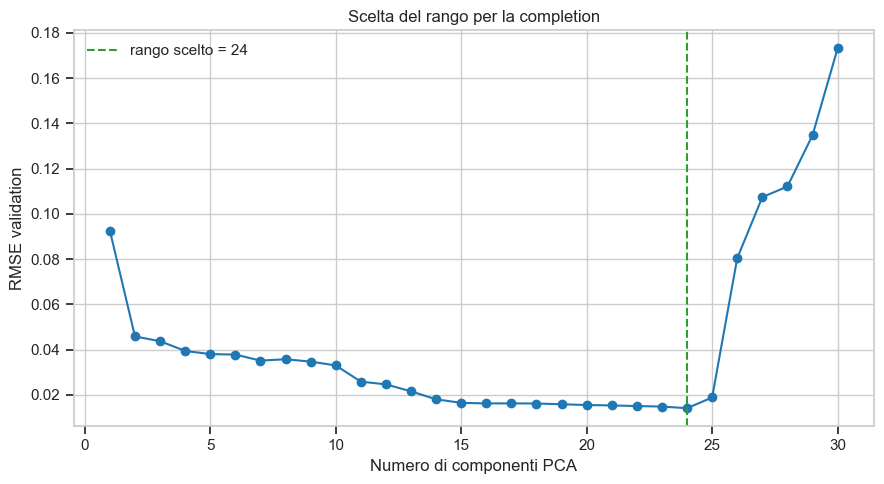

In [42]:
def low_rank_completion(X_true, M, pca_model, means, n_iter=30):
    X_hat = X_true.copy()
    X_hat[~M] = np.broadcast_to(means, X_true.shape)[~M]
    for _ in range(n_iter):
        low_rank = pca_model.inverse_transform(pca_model.transform(X_hat))
        X_hat[~M] = low_rank[~M]
        X_hat[M] = X_true[M]
    return np.clip(X_hat, 0, 1)

completion_iterations = 30
rank_validation_masks = [M_val] + [
    make_mask(len(X_val), d, selected_features, hidden_fraction, seed=seed)
    for seed in range(102, 106)
]
rank_scores = []
for candidate_rank in range(1, d + 1):
    candidate_pca = PCA(n_components=candidate_rank).fit(X_train)
    squared_error, absolute_error, n_hidden = 0.0, 0.0, 0
    for validation_mask in rank_validation_masks:
        validation_input = observed_with_mean(X_val, validation_mask, column_means)
        validation_hat = low_rank_completion(
            validation_input, validation_mask, candidate_pca, column_means,
            n_iter=completion_iterations,
        )
        errors = X_val[~validation_mask] - validation_hat[~validation_mask]
        squared_error += np.square(errors).sum()
        absolute_error += np.abs(errors).sum()
        n_hidden += errors.size
    rank_scores.append({
        "rango": candidate_rank,
        "RMSE validation": np.sqrt(squared_error / n_hidden),
        "MAE validation": absolute_error / n_hidden,
        "varianza cumulativa": candidate_pca.explained_variance_ratio_.sum(),
    })
rank_scores = pd.DataFrame(rank_scores)
rank = int(rank_scores.loc[rank_scores["RMSE validation"].idxmin(), "rango"])
print(f"Rango PCA scelto sulla validation: {rank}")
display(rank_scores.nsmallest(10, "RMSE validation").round(4))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(rank_scores["rango"], rank_scores["RMSE validation"], "o-")
ax.axvline(rank, color="tab:green", ls="--", label=f"rango scelto = {rank}")
ax.set(xlabel="Numero di componenti PCA", ylabel="RMSE validation")
ax.set_title("Scelta del rango per la completion")
ax.legend()
plt.tight_layout()
plt.show()

pca_rank = PCA(n_components=rank).fit(X_train)
X_val_lowrank = low_rank_completion(
    X_val_input, M_val, pca_rank, column_means, n_iter=completion_iterations
)
X_test_lowrank = low_rank_completion(
    X_test_input, M_test, pca_rank, column_means, n_iter=completion_iterations
)

# Variante a rango fisso 6, distinto dal rango scelto sulla validation.
fixed_rank = 6
pca_rank6 = PCA(n_components=fixed_rank).fit(X_train)
X_val_lowrank_r6 = low_rank_completion(
    X_val_input, M_val, pca_rank6, column_means, n_iter=completion_iterations
)
X_test_lowrank_r6 = low_rank_completion(
    X_test_input, M_test, pca_rank6, column_means, n_iter=completion_iterations
)


## 9. Completion con SVD esplicita

Centriamo il training con la sua media $\mu$ e calcoliamo direttamente `np.linalg.svd`. Le prime $r$ righe di $V^{\mathsf T}$ forniscono le direzioni delle feature. Per una nuova riga, adattiamo i suoi coefficienti $z_i$ usando **soltanto le coordinate osservate**. Il problema risolto è:

$$
z_i=\underset{z}{\operatorname{argmin}}\left[\sum_{j:M_{ij}=1}\bigl(X_{ij}-\mu_j-(V_rz)_j\bigr)^2+\lambda\lVert z\rVert_2^2\right]
$$

Qui $V_r$ contiene le prime $r$ direzioni SVD come colonne e $\lambda=0{,}001$ stabilizza la soluzione quando restano poche coordinate osservate. Per ogni cella nascosta usiamo $\widehat X_{ij}=\mu_j+(V_rz_i)_j$; le celle osservate non vengono modificate. La stima finale è limitata a $[0,1]$.

Anche la SVD prova i ranghi da 1 a 30 e sceglie il proprio minimo RMSE aggregato sulle **stesse cinque maschere di validation** usate per la PCA. La fattorizzazione è calcolata una sola volta sul training completo. Il metodo non usa i valori nascosti di validation o test per stimare i coefficienti.

PCA e SVD condividono le direzioni del training, ma le procedure con cui ricostruiscono una riga incompleta sono diverse; per questo le confrontiamo come due righe separate nelle tabelle dei risultati.


Rango SVD scelto sulla validation: 24


,rango,RMSE validation,MAE validation
23,24,0.0140,0.0089
22,23,0.0148,0.0102
21,22,0.0150,0.0104
20,21,0.0153,0.0110
19,20,0.0154,0.0113
18,19,0.0158,0.0114
17,18,0.0161,0.0119
15,16,0.0161,0.0118
16,17,0.0162,0.0120
14,15,0.0164,0.0119


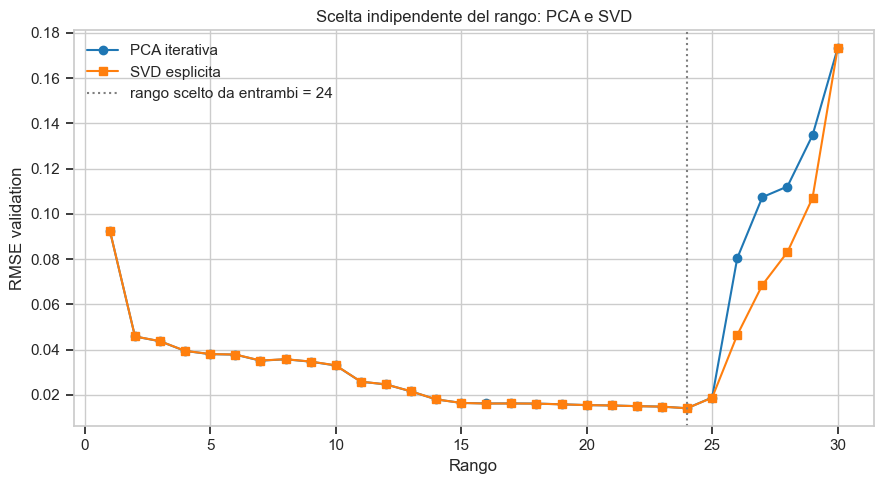

In [43]:
# SVD esplicita del solo training centrato.
svd_mean = X_train.mean(axis=0)
svd_U, svd_singular_values, svd_Vt = np.linalg.svd(
    X_train - svd_mean, full_matrices=False
)
svd_regularization = 1e-3

def svd_completion(X_input, M, mean, right_vectors, rank, ridge=1e-3):
    """Stima i coefficienti SVD da coordinate osservate, riga per riga."""
    V_r = right_vectors[:rank].T  # feature x componenti
    X_hat = X_input.copy()
    penalty = ridge * np.eye(rank)
    for i in range(len(X_input)):
        missing = ~M[i]
        if not missing.any():
            continue
        observed = M[i]
        basis = V_r[observed]
        residual = X_input[i, observed] - mean[observed]
        scores = np.linalg.solve(
            basis.T @ basis + penalty, basis.T @ residual
        )
        X_hat[i, missing] = mean[missing] + V_r[missing] @ scores
    return np.clip(X_hat, 0, 1)

svd_rank_scores = []
for candidate_rank in range(1, d + 1):
    squared_error, absolute_error, n_hidden = 0.0, 0.0, 0
    for validation_mask in rank_validation_masks:
        validation_input = observed_with_mean(
            X_val, validation_mask, column_means
        )
        validation_hat = svd_completion(
            validation_input, validation_mask, svd_mean, svd_Vt,
            candidate_rank, ridge=svd_regularization,
        )
        errors = X_val[~validation_mask] - validation_hat[~validation_mask]
        squared_error += np.square(errors).sum()
        absolute_error += np.abs(errors).sum()
        n_hidden += errors.size
    svd_rank_scores.append({
        "rango": candidate_rank,
        "RMSE validation": np.sqrt(squared_error / n_hidden),
        "MAE validation": absolute_error / n_hidden,
    })
svd_rank_scores = pd.DataFrame(svd_rank_scores)
svd_rank = int(svd_rank_scores.loc[
    svd_rank_scores["RMSE validation"].idxmin(), "rango"
])
print(f"Rango SVD scelto sulla validation: {svd_rank}")
display(svd_rank_scores.nsmallest(10, "RMSE validation").round(4))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(rank_scores["rango"], rank_scores["RMSE validation"],
        "o-", label="PCA iterativa")
ax.plot(svd_rank_scores["rango"], svd_rank_scores["RMSE validation"],
        "s-", label="SVD esplicita")
if rank == svd_rank:
    ax.axvline(rank, color="tab:gray", ls=":", label=f"rango scelto da entrambi = {rank}")
else:
    ax.axvline(rank, color="tab:blue", ls=":", label=f"rango PCA = {rank}")
    ax.axvline(svd_rank, color="tab:orange", ls=":", label=f"rango SVD = {svd_rank}")
ax.set(xlabel="Rango", ylabel="RMSE validation")
ax.set_title("Scelta indipendente del rango: PCA e SVD")
ax.legend()
plt.tight_layout()
plt.show()

X_val_svd = svd_completion(
    X_val_input, M_val, svd_mean, svd_Vt, svd_rank, ridge=svd_regularization
)
X_test_svd = svd_completion(
    X_test_input, M_test, svd_mean, svd_Vt, svd_rank, ridge=svd_regularization
)

X_val_svd_r6 = svd_completion(
    X_val_input, M_val, svd_mean, svd_Vt, fixed_rank, ridge=svd_regularization
)
X_test_svd_r6 = svd_completion(
    X_test_input, M_test, svd_mean, svd_Vt, fixed_rank, ridge=svd_regularization
)


### 9.1 PCA e SVD con la stessa procedura di completion

PCA e SVD della stessa matrice centrata individuano gli stessi sottospazi principali. Le singole direzioni possono differire di segno (o di una rotazione all'interno di un sottospazio con valori singolari uguali); il proiettore $V_rV_r^{\mathsf T}$ resta uguale quando è selezionato lo stesso sottospazio.

Per isolare la scelta della base dalla procedura di completion, usiamo **la stessa funzione `svd_completion`** con due basi: `PCA(svd_solver="full").components_` e `np.linalg.svd(...).Vt`. La PCA usa qui il solver SVD completo per rendere il confronto deterministico. Per ogni rango da 1 a 30 manteniamo identici training, media, maschera, input, penalizzazione isotropa $\lambda=10^{-3}$ e clipping finale.

In entrambi i casi stimiamo i coefficienti dalle sole coordinate osservate:

$$
\widehat z=\arg\min_z\left\|x_O-\mu_O-V_{r,O}z\right\|_2^2+\lambda\|z\|_2^2,
\qquad \widehat x_H=\mu_H+V_{r,H}\widehat z.
$$

Una trasformazione ortogonale della base cambia i coefficienti latenti ma preserva la ricostruzione e la penalizzazione. Ci aspettiamo quindi previsioni e RMSE uguali entro la precisione numerica **anche dopo la 25-esima componente**. La tabella mostra la differenza massima sulle celle nascoste di validation e test, oltre alla differenza tra i proiettori. I grafici sovrappongono le due curve di RMSE. Questa verifica riguarda la procedura comune ai due sottospazi: il confronto precedente resta tra PCA iterativa e SVD regolarizzata.


,split,rango,RMSE PCA (procedura comune),RMSE SVD (procedura comune),differenza RMSE,max differenza celle nascoste,max differenza proiettori
0,Validation,1,0.103192,0.103192,0.0,0.0,0.0
1,Test,1,0.093848,0.093848,0.0,0.0,0.0
2,Validation,2,0.048183,0.048183,0.0,0.0,0.0
3,Test,2,0.053162,0.053162,0.0,0.0,0.0
4,Validation,3,0.046702,0.046702,0.0,0.0,0.0
5,Test,3,0.049276,0.049276,0.0,0.0,0.0
6,Validation,4,0.044161,0.044161,0.0,0.0,0.0
7,Test,4,0.042019,0.042019,0.0,0.0,0.0
8,Validation,5,0.042302,0.042302,0.0,0.0,0.0
9,Test,5,0.045255,0.045255,0.0,0.0,0.0


Massima differenza nelle celle nascoste su tutti i ranghi e split: 0.000e+00
Massima differenza RMSE: 0.000e+00


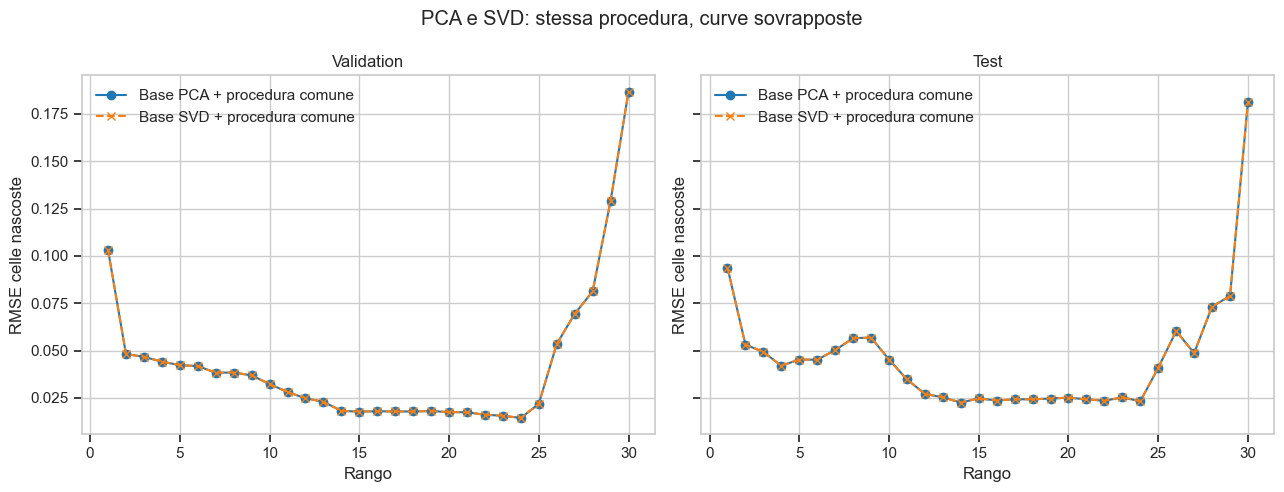

In [44]:
# Stesse basi principali, stessa procedura di completion, tutti i ranghi.
pca_common = PCA(n_components=d, svd_solver="full").fit(X_train)
np.testing.assert_allclose(pca_common.mean_, svd_mean, atol=1e-12, rtol=0)
common_completion_rows = []

for common_rank in range(1, d + 1):
    pca_basis = pca_common.components_[:common_rank].T
    svd_basis = svd_Vt[:common_rank].T
    projector_gap = np.max(np.abs(
        pca_basis @ pca_basis.T - svd_basis @ svd_basis.T
    ))
    np.testing.assert_allclose(
        pca_basis @ pca_basis.T, svd_basis @ svd_basis.T,
        atol=1e-10, rtol=1e-10,
    )
    for split_name, truth, input_matrix, mask in [
        ("Validation", X_val, X_val_input, M_val),
        ("Test", X_test, X_test_input, M_test),
    ]:
        # Cambia soltanto la base passata alla stessa funzione.
        pca_hat_common = svd_completion(
            input_matrix, mask, svd_mean, pca_common.components_,
            common_rank, ridge=svd_regularization,
        )
        svd_hat_common = svd_completion(
            input_matrix, mask, svd_mean, svd_Vt,
            common_rank, ridge=svd_regularization,
        )
        np.testing.assert_allclose(
            pca_hat_common, svd_hat_common, atol=1e-10, rtol=1e-10
        )
        pca_rmse = evaluate(truth, pca_hat_common, mask, "PCA", split_name)["RMSE"]
        svd_rmse = evaluate(truth, svd_hat_common, mask, "SVD", split_name)["RMSE"]
        common_completion_rows.append({
            "split": split_name,
            "rango": common_rank,
            "RMSE PCA (procedura comune)": pca_rmse,
            "RMSE SVD (procedura comune)": svd_rmse,
            "differenza RMSE": abs(pca_rmse - svd_rmse),
            "max differenza celle nascoste": np.max(np.abs(
                pca_hat_common[~mask] - svd_hat_common[~mask]
            )),
            "max differenza proiettori": projector_gap,
        })

common_completion_results = pd.DataFrame(common_completion_rows)
display(common_completion_results)
print("Massima differenza nelle celle nascoste su tutti i ranghi e split:",
      f"{common_completion_results['max differenza celle nascoste'].max():.3e}")
print("Massima differenza RMSE:",
      f"{common_completion_results['differenza RMSE'].max():.3e}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, split_name in zip(axes, ["Validation", "Test"]):
    split_rows = common_completion_results.query("split == @split_name")
    ax.plot(split_rows["rango"], split_rows["RMSE PCA (procedura comune)"],
            "o-", label="Base PCA + procedura comune")
    ax.plot(split_rows["rango"], split_rows["RMSE SVD (procedura comune)"],
            "x--", label="Base SVD + procedura comune")
    ax.set(title=split_name, xlabel="Rango", ylabel="RMSE celle nascoste")
    ax.legend()
fig.suptitle("PCA e SVD: stessa procedura, curve sovrapposte")
plt.tight_layout()
plt.show()


## 10. Confronto quantitativo e errori per feature

La tabella confronta i **nove metodi** sulle stesse celle nascoste della validation e, separatamente, del test. Riporta RMSE, MAE, $R^2$ e numero di celle valutate. Le varianti complete e mascherate di regressione lineare e Ridge compaiono separatamente. PCA e SVD compaiono sia con il rango scelto sulla validation sia con rango fisso $r=6$. I due grafici visualizzano RMSE e MAE; un'ulteriore tabella mostra l'RMSE **per ciascuna delle tre feature target nel test**.


,split,metodo,RMSE,MAE,R2,entry valutate
0,Validation,Media,0.1867,0.1412,0.0536,74
1,Validation,Lineare matriciale (completo),0.0130,0.0082,0.9954,74
2,Validation,Lineare matriciale (complete-case),0.0140,0.0085,0.9947,74
3,Validation,Ridge matriciale (completo),0.0127,0.0082,0.9956,74
4,Validation,Ridge matriciale (complete-case),0.0144,0.0094,0.9944,74
5,Validation,"PCA (r=24, validation)",0.0144,0.0096,0.9943,74
6,Validation,"SVD (r=24, validation)",0.0144,0.0096,0.9943,74
7,Validation,PCA (r=6),0.0418,0.0312,0.9525,74
8,Validation,SVD (r=6),0.0418,0.0312,0.9524,74
9,Test,Media,0.1814,0.1417,0.0799,50


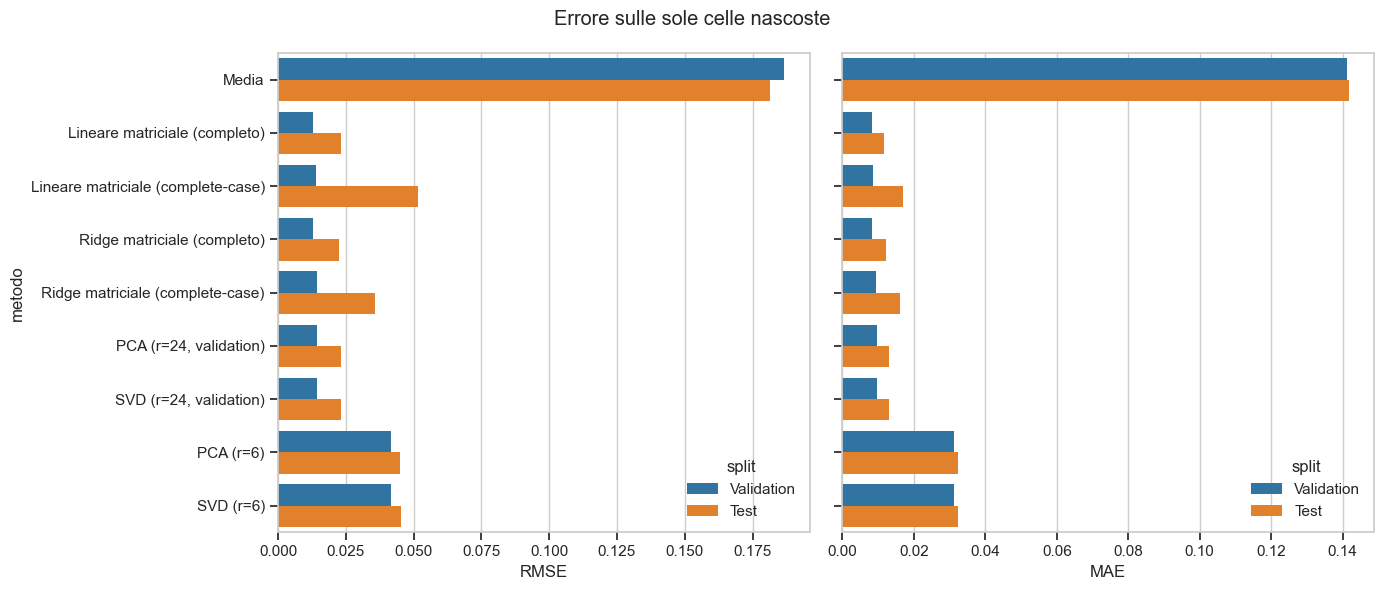

In [45]:
method_names = {
    "mean": "Media",
    "linear": "Lineare matriciale (completo)",
    "linear_masked": "Lineare matriciale (complete-case)",
    "ridge": "Ridge matriciale (completo)",
    "ridge_masked": "Ridge matriciale (complete-case)",
    "pca": f"PCA (r={rank}, validation)",
    "svd": f"SVD (r={svd_rank}, validation)",
    "pca_r6": "PCA (r=6)",
    "svd_r6": "SVD (r=6)",
}
completion_results = [
    ("mean", X_val_mean, X_test_mean),
    ("linear", X_val_linear, X_test_linear),
    ("linear_masked", X_val_linear_masked, X_test_linear_masked),
    ("ridge", X_val_ridge, X_test_ridge),
    ("ridge_masked", X_val_ridge_masked, X_test_ridge_masked),
    ("pca", X_val_lowrank, X_test_lowrank),
    ("svd", X_val_svd, X_test_svd),
    ("pca_r6", X_val_lowrank_r6, X_test_lowrank_r6),
    ("svd_r6", X_val_svd_r6, X_test_svd_r6),
]
results = pd.DataFrame(
    [evaluate(X_val, val_hat, M_val, method_names[key], "Validation")
     for key, val_hat, _ in completion_results]
    + [evaluate(X_test, test_hat, M_test, method_names[key], "Test")
       for key, _, test_hat in completion_results]
)
display(results.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
sns.barplot(data=results, x="RMSE", y="metodo", hue="split", ax=ax[0])
sns.barplot(data=results, x="MAE", y="metodo", hue="split", ax=ax[1])
for a in ax:
    a.set_xlim(left=0)
fig.suptitle("Errore sulle sole celle nascoste")
plt.tight_layout()
plt.show()


metodo,Lineare matriciale (complete-case),Lineare matriciale (completo),Media,"PCA (r=24, validation)",PCA (r=6),Ridge matriciale (complete-case),Ridge matriciale (completo),"SVD (r=24, validation)",SVD (r=6)
feature,,,,,,,,,
mean_concavity,0.0884,0.0391,0.1705,0.0393,0.0612,0.0600,0.0379,0.0391,0.0612
mean_radius,0.0030,0.0026,0.1745,0.0042,0.0307,0.0047,0.0031,0.0041,0.0309
worst_radius,0.0080,0.0060,0.2023,0.0067,0.0380,0.0120,0.0076,0.0067,0.0381


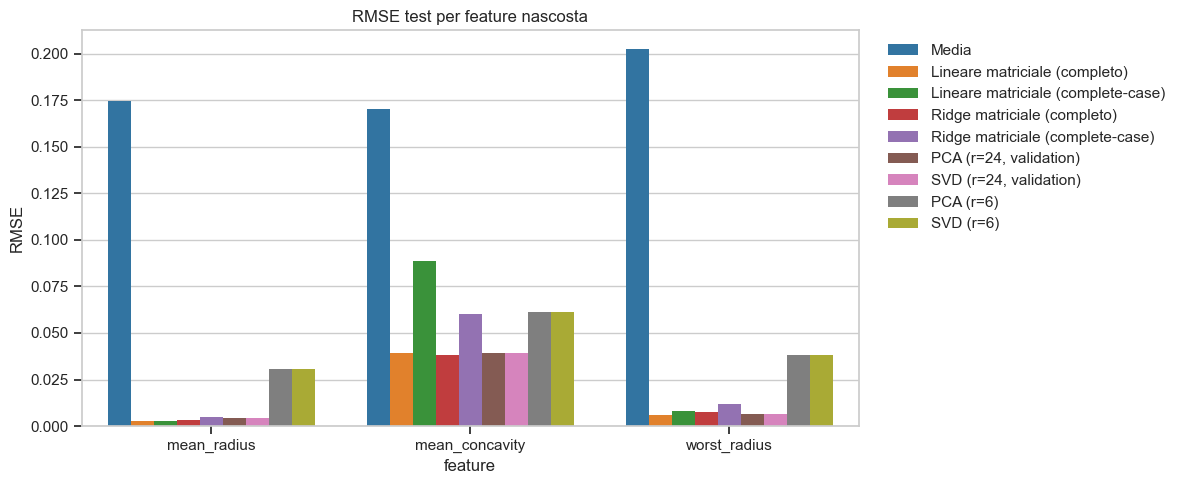

In [46]:
# Errore per feature sul test: distingue le colonne più difficili.
per_feature = []
for key, _, X_hat in completion_results:
    for j in selected_features:
        miss = ~M_test[:, j]
        per_feature.append({
            "metodo": method_names[key],
            "feature": feature_names[j],
            "RMSE": np.sqrt(mean_squared_error(X_test[miss, j], X_hat[miss, j])),
        })
per_feature = pd.DataFrame(per_feature)
display(per_feature.pivot(index="feature", columns="metodo", values="RMSE").round(4))
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=per_feature, x="feature", y="RMSE", hue="metodo", ax=ax)
ax.set_title("RMSE test per feature nascosta")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 11. Cambiare quali feature vengono nascoste

Confrontiamo sul test due gruppi di tre feature: quello principale (`mean_radius`, `mean_concavity`, `worst_radius`) e un gruppo tutto legato al raggio (`mean_radius`, `radius_error`, `worst_radius`). Per ciascun gruppo il codice genera una nuova maschera con probabilità di occultamento del 30% per feature.

Le regressioni lineari e Ridge vengono riaddestrate sullo **stesso training**, usando come target le feature del gruppo corrente; per le varianti mascherate viene creata anche una maschera di training corrispondente. Le medie della baseline, la PCA e la SVD addestrate in precedenza restano fisse. Il confronto mostra come cambia l'errore quando cambiano le colonne da prevedere; le due prove riguardano target diversi e non isolano la sola disposizione delle celle mancanti a target fissi.


In [47]:
def predict_all_methods(test_input, masked_input, M, *, means, linear, linear_pred,
                        linear_masked, linear_masked_pred, ridge, ridge_pred,
                        ridge_masked, ridge_masked_pred, pca_model, svd_model,
                        pca6_model, svd6_rank):
    """Calcola le nove completion per una maschera e i modelli specificati."""
    return [
        ("mean", mean_completion(test_input, M, means)),
        ("linear", regression_completion(test_input, M, linear, linear_pred)),
        ("linear_masked", regression_completion(
            masked_input, M, linear_masked, linear_masked_pred
        )),
        ("ridge", regression_completion(test_input, M, ridge, ridge_pred)),
        ("ridge_masked", regression_completion(
            masked_input, M, ridge_masked, ridge_masked_pred
        )),
        ("pca", low_rank_completion(test_input, M, pca_model, means)),
        ("svd", svd_completion(
            test_input, M, svd_mean, svd_Vt, svd_model,
            ridge=svd_regularization
        )),
        ("pca_r6", low_rank_completion(
            test_input, M, pca6_model, means
        )),
        ("svd_r6", svd_completion(
            test_input, M, svd_mean, svd_Vt, svd6_rank,
            ridge=svd_regularization
        )),
    ]


,split,metodo,RMSE,MAE,R2,entry valutate
0,"distribuito (mean radius, concavity, worst rad...",Media,0.1770,0.1478,0.1087,47
1,"distribuito (mean radius, concavity, worst rad...",Lineare matriciale (completo),0.0241,0.0120,0.9835,47
2,"distribuito (mean radius, concavity, worst rad...",Lineare matriciale (complete-case),0.0372,0.0163,0.9606,47
3,"distribuito (mean radius, concavity, worst rad...",Ridge matriciale (completo),0.0206,0.0116,0.9880,47
4,"distribuito (mean radius, concavity, worst rad...",Ridge matriciale (complete-case),0.0273,0.0145,0.9787,47
5,"distribuito (mean radius, concavity, worst rad...","PCA (r=24, validation)",0.0246,0.0132,0.9828,47
6,"distribuito (mean radius, concavity, worst rad...","SVD (r=24, validation)",0.0245,0.0132,0.9829,47
7,"distribuito (mean radius, concavity, worst rad...",PCA (r=6),0.0523,0.0340,0.9221,47
8,"distribuito (mean radius, concavity, worst rad...",SVD (r=6),0.0523,0.0340,0.9222,47
9,concentrato (radius family),Media,0.1738,0.1447,0.2413,47


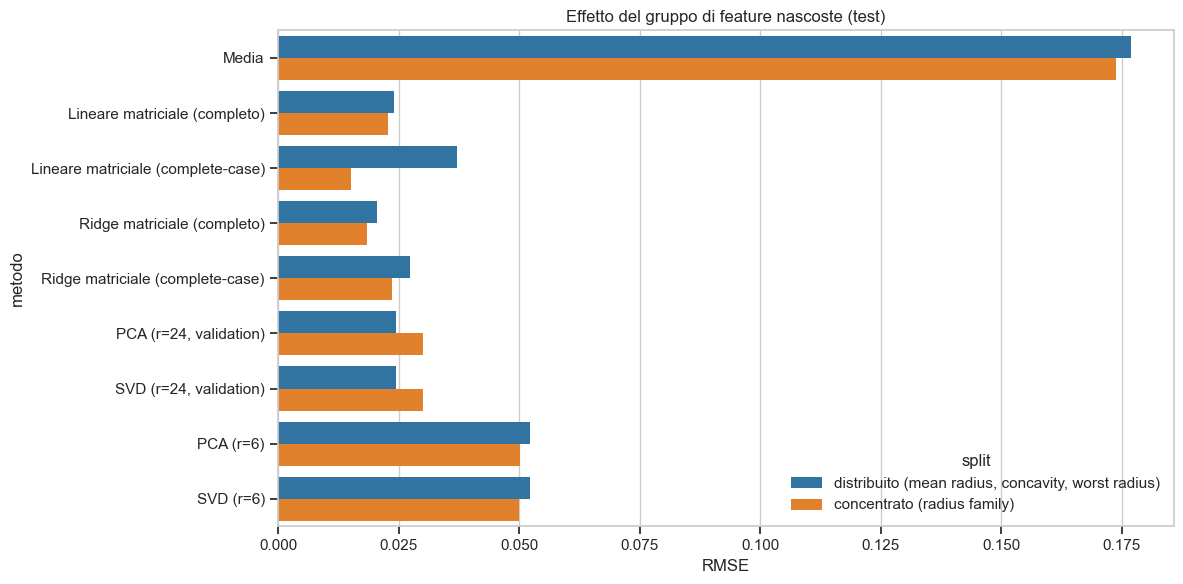

In [48]:
patterns = {
    "distribuito (mean radius, concavity, worst radius)": [0, 6, 20],
    "concentrato (radius family)": [0, 10, 20],
}
pattern_rows = []
for label, targets in patterns.items():
    M = make_mask(len(X_test), d, targets, hidden_fraction, seed=303)
    pattern_train_mask = make_mask(len(X_train), d, targets, hidden_fraction, seed=304)
    pattern_linear_models, pattern_linear_predictors = fit_regression_completion(
        X_train, targets, LinearRegression
    )
    pattern_masked_linear_models, pattern_masked_linear_predictors, pattern_means = (
        fit_masked_regression_completion(
            X_train, pattern_train_mask, targets, LinearRegression
        )
    )
    pattern_ridge_models, pattern_ridge_predictors = fit_regression_completion(
        X_train, targets, ridge_estimator
    )
    pattern_masked_ridge_models, pattern_masked_ridge_predictors, ridge_pattern_means = (
        fit_masked_regression_completion(
            X_train, pattern_train_mask, targets, ridge_estimator
        )
    )
    np.testing.assert_allclose(pattern_means, ridge_pattern_means)
    test_input = observed_with_mean(X_test, M, column_means)
    masked_test_input = observed_with_mean(X_test, M, pattern_means)
    predictions = predict_all_methods(
        test_input, masked_test_input, M, means=column_means,
        linear=pattern_linear_models, linear_pred=pattern_linear_predictors,
        linear_masked=pattern_masked_linear_models,
        linear_masked_pred=pattern_masked_linear_predictors,
        ridge=pattern_ridge_models, ridge_pred=pattern_ridge_predictors,
        ridge_masked=pattern_masked_ridge_models,
        ridge_masked_pred=pattern_masked_ridge_predictors,
        pca_model=pca_rank, svd_model=svd_rank,
        pca6_model=pca_rank6, svd6_rank=fixed_rank,
    )
    for key, hat in predictions:
        pattern_rows.append(evaluate(X_test, hat, M, method_names[key], label))
pattern_results = pd.DataFrame(pattern_rows)
display(pattern_results.round(4))
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=pattern_results, x="RMSE", y="metodo", hue="split", ax=ax)
ax.set_title("Effetto del gruppo di feature nascoste (test)")
plt.tight_layout()
plt.show()


### Sensibilità alla probabilità di occultamento

Manteniamo le tre feature target principali e valutiamo sul test probabilità di occultamento del **10%, 30%, 50% e 70%** per ciascuna di esse. Per ogni probabilità viene generata una maschera riproducibile con lo stesso seed. I nove metodi già addestrati e le medie restano fissi: cambiano soltanto le celle da completare e valutare.

La tabella riporta l'RMSE sulle celle nascoste a ciascun livello. Poiché cambia anche l'insieme delle celle valutate, l'RMSE non deve necessariamente crescere in modo monotono al crescere della probabilità. Il grafico serve a osservare empiricamente questa sensibilità.


metodo,Lineare matriciale (complete-case),Lineare matriciale (completo),Media,"PCA (r=24, validation)",PCA (r=6),Ridge matriciale (complete-case),Ridge matriciale (completo),"SVD (r=24, validation)",SVD (r=6)
split,,,,,,,,,
10% nascosto,0.0092,0.0087,0.1722,0.0100,0.0268,0.0094,0.0089,0.0098,0.0267
30% nascosto,0.0203,0.0185,0.1697,0.0233,0.0447,0.0181,0.0182,0.0233,0.0447
50% nascosto,0.0169,0.0163,0.1713,0.0201,0.0415,0.0153,0.0160,0.0200,0.0415
70% nascosto,0.0341,0.0174,0.1761,0.0195,0.0457,0.0243,0.0172,0.0194,0.0457


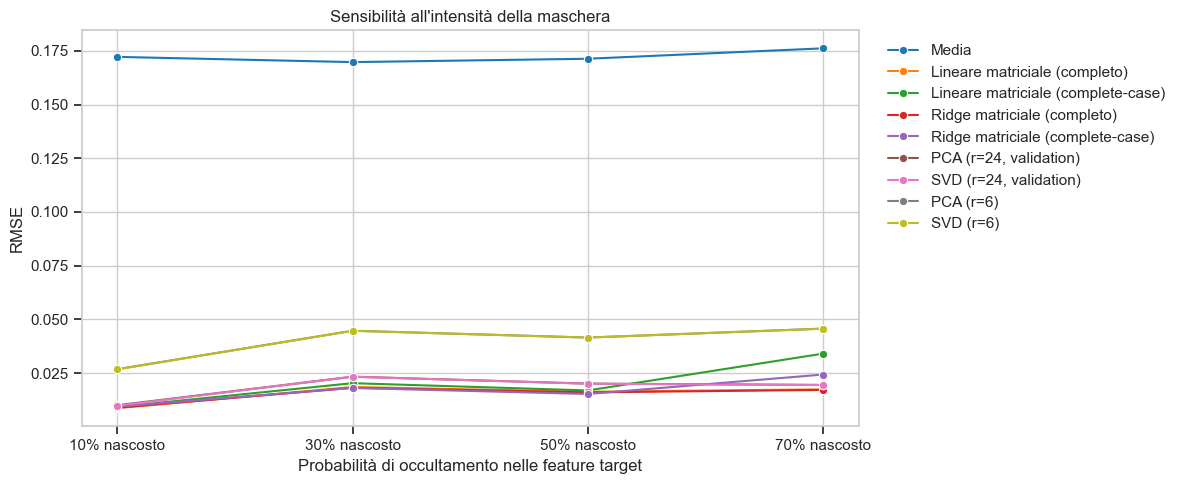

In [49]:
sensitivity_rows = []
for frac in [0.10, 0.30, 0.50, 0.70]:
    M = make_mask(len(X_test), d, selected_features, frac, seed=404)
    test_input = observed_with_mean(X_test, M, column_means)
    masked_input = observed_with_mean(X_test, M, masked_train_means)
    predictions = predict_all_methods(
        test_input, masked_input, M, means=column_means,
        linear=linear_models, linear_pred=linear_predictors,
        linear_masked=masked_linear_models,
        linear_masked_pred=masked_linear_predictors,
        ridge=ridge_models, ridge_pred=ridge_predictors,
        ridge_masked=masked_ridge_models,
        ridge_masked_pred=masked_ridge_predictors,
        pca_model=pca_rank, svd_model=svd_rank,
        pca6_model=pca_rank6, svd6_rank=fixed_rank,
    )
    for key, hat in predictions:
        sensitivity_rows.append(evaluate(
            X_test, hat, M, method_names[key], f"{frac:.0%} nascosto"
        ))
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.pivot(index="split", columns="metodo", values="RMSE").round(4))
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=sensitivity, x="split", y="RMSE", hue="metodo",
             marker="o", sort=False, ax=ax)
ax.set_title("Sensibilità all'intensità della maschera")
ax.set_xlabel("Probabilità di occultamento nelle feature target")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 12. Interpretazione

OLS e Ridge stimano una matrice di coefficienti con tre output a partire da 27 predittori comuni. I target osservati non vengono impiegati come input. La variante mascherata restringe il training alle righe con tutte le risposte osservate; il confronto cambia quindi anche il numero di righe di training. Le tabelle e figure sopra sono ricalcolate e non ereditano i risultati del notebook originale. PCA, SVD e baseline mantengono le loro procedure originali.


## 13. Required check: SVD troncata e proiettori

Verifichiamo il controllo richiesto in **homework_ch1_4_completion 1.pdf**, sezione *One required check*. Usiamo la stessa matrice del training centrata già fattorizzata nella sezione 9, $X_c=X_{\mathrm{train}}-\mu$, e scegliamo il rango fisso $r=6$. Questo rango serve alla verifica algebrica; non viene selezionato sul test.

Dalla SVD $X_c=U\Sigma V^{\mathsf T}$ costruiamo
$$
X_r=U_r\Sigma_r V_r^{\mathsf T},\qquad
P_r^{(s)}=U_rU_r^{\mathsf T},\qquad
P_r^{(f)}=V_rV_r^{\mathsf T}.
$$
Il proiettore $P_r^{(s)}$ agisce nello spazio delle osservazioni (426 dimensioni), mentre $P_r^{(f)}$ agisce nello spazio delle feature (30 dimensioni). Confrontiamo numericamente
$$
P_r^{(s)}X_c\approx X_cP_r^{(f)}\approx
P_r^{(s)}X_cP_r^{(f)}\approx X_r.
$$
La tabella riporta, per ogni coppia, la norma di Frobenius dello scarto, lo scarto relativo rispetto a $\|X_r\|_F$ e il massimo scarto assoluto per cella. Gli assert verificano le uguaglianze con tolleranza $10^{-10}$.


In [17]:
# Required check: riuso della SVD del training centrato, senza nuovi fit.
check_rank = 6
X_centered_check = X_train - svd_mean
U_r_check = svd_U[:, :check_rank]
s_r_check = svd_singular_values[:check_rank]
V_r_check = svd_Vt[:check_rank].T
X_r_check = (U_r_check * s_r_check) @ V_r_check.T
P_samples_check = U_r_check @ U_r_check.T
P_features_check = V_r_check @ V_r_check.T

check_matrices = {
    "P_s X_c": P_samples_check @ X_centered_check,
    "X_c P_f": X_centered_check @ P_features_check,
    "P_s X_c P_f": P_samples_check @ X_centered_check @ P_features_check,
    "X_r": X_r_check,
}
print(f"X_c: {X_centered_check.shape}; r = {check_rank}; "
      f"P_s: {P_samples_check.shape}; P_f: {P_features_check.shape}")
check_rows = []
check_names = list(check_matrices)
reference_norm = np.linalg.norm(X_r_check, ord="fro")
for i, left in enumerate(check_names):
    for right in check_names[i + 1:]:
        difference = check_matrices[left] - check_matrices[right]
        frobenius_gap = np.linalg.norm(difference, ord="fro")
        check_rows.append({
            "confronto": f"{left} vs {right}",
            "scarto Frobenius": frobenius_gap,
            "scarto relativo": frobenius_gap / reference_norm,
            "max scarto assoluto": np.max(np.abs(difference)),
        })
        np.testing.assert_allclose(check_matrices[left], check_matrices[right],
                                   atol=1e-10, rtol=1e-10)
required_check_results = pd.DataFrame(check_rows)
display(required_check_results.style.format({
    "scarto Frobenius": "{:.3e}",
    "scarto relativo": "{:.3e}",
    "max scarto assoluto": "{:.3e}",
}))

# Un proiettore ortogonale è simmetrico e idempotente, ma non è l'identità.
projector_rows = []
for label, projector in [("P_s (osservazioni)", P_samples_check),
                          ("P_f (feature)", P_features_check)]:
    identity = np.eye(projector.shape[0])
    np.testing.assert_allclose(projector, projector.T, atol=1e-10, rtol=1e-10)
    np.testing.assert_allclose(projector @ projector, projector,
                               atol=1e-10, rtol=1e-10)
    projector_rank = np.linalg.matrix_rank(projector)
    assert projector_rank == check_rank < projector.shape[0]
    projector_rows.append({
        "proiettore": label,
        "dimensione ambiente": projector.shape[0],
        "rango": projector_rank,
        "scarto idempotenza (Frobenius)": np.linalg.norm(
            projector @ projector - projector, ord="fro"),
        "distanza da identità (Frobenius)": np.linalg.norm(
            projector - identity, ord="fro"),
    })
projector_check_results = pd.DataFrame(projector_rows)
display(projector_check_results.style.format({
    "scarto idempotenza (Frobenius)": "{:.3e}",
    "distanza da identità (Frobenius)": "{:.6f}",
}))
print("Required check superato: le quattro ricostruzioni coincidono entro 1e-10.")
print("Errore relativo della troncatura ||X_c - X_r||_F / ||X_c||_F:",
      f"{np.linalg.norm(X_centered_check - X_r_check, ord='fro') / np.linalg.norm(X_centered_check, ord='fro'):.6f}")


X_c: (426, 30); r = 6; P_s: (426, 426); P_f: (30, 30)
Required check superato: le quattro ricostruzioni coincidono entro 1e-10.
Errore relativo della troncatura ||X_c - X_r||_F / ||X_c||_F: 0.299498


,confronto,scarto Frobenius,scarto relativo,max scarto assoluto
0,P_s X_c vs X_c P_f,2.287e-14,1.406e-15,2.304e-15
1,P_s X_c vs P_s X_c P_f,1.473e-14,9.059e-16,1.332e-15
2,P_s X_c vs X_r,1.524e-14,9.371e-16,1.332e-15
3,X_c P_f vs P_s X_c P_f,1.824e-14,1.122e-15,2.331e-15
4,X_c P_f vs X_r,1.955e-14,1.202e-15,2.331e-15
5,P_s X_c P_f vs X_r,1.355e-14,8.331e-16,7.772e-16


,proiettore,dimensione ambiente,rango,scarto idempotenza (Frobenius),distanza da identità (Frobenius)
0,P_s (osservazioni),426,6,2.117e-15,20.493902
1,P_f (feature),30,6,3.398e-15,4.898979


### Perché i proiettori non sono l'identità

Le uguaglianze seguono dall'ortogonalità dei vettori singolari: moltiplicare $X_c$ per uno dei due proiettori conserva soltanto i primi $r$ termini della SVD. Applicare anche il secondo proiettore non cambia la matrice già troncata.

Questo non implica $P_r^{(s)}=I$ o $P_r^{(f)}=I$: entrambi hanno rango 6, inferiore rispettivamente a 426 e 30, e annullano le direzioni ortogonali ai sottospazi selezionati. La loro distanza dall'identità è $\|P-I_m\|_F=\sqrt{m-r}$: circa 20,493902 per le osservazioni e 4,898979 per le feature. Sono identità solo **sul proprio sottospazio**, non sull'intero spazio ambiente. Inoltre $X_r$ è un'approssimazione di $X_c$: lo scarto di troncatura stampato sopra è distinto dagli scarti di arrotondamento tra le quattro forme equivalenti.
